# Ratio de Sharpe et corrélations

Le notebook 05 mesurait le risque de trois ETF répliquant le STOXX Europe 600.
Celui-ci rapporte le rendement au risque pris, puis mesure à quel point les trois
fonds bougent ensemble — et ce que cela implique pour la diversification.

Données : MEUD.PA (Amundi), ETZ.PA (BNP Paribas Easy), EXSA.DE (iShares),
660 séances communes du 19 février 2024 au 25 septembre 2026, cours de clôture
ajustés figés dans `data/etf_europe.csv`.

Auteur : KOULEKPOTO Yao Eloge Crédo — octobre 2026

## 1. Ratio de Sharpe

Le ratio de Sharpe rapporte le rendement obtenu **au-delà d'un placement sans risque**
au risque supporté pour l'obtenir :

> (rendement annualisé − taux sans risque) / volatilité annualisée


In [69]:
import pandas as pd
etf_eur = pd.read_csv("data/etf_europe.csv", index_col="Date", parse_dates=True)
etf_eur = etf_eur.dropna()
etf_eur

,ETZ.PA,EXSA.DE,MEUD.PA
Date,,,
2024-02-19,15.112000,45.084953,223.820007
2024-02-20,15.094000,45.010891,223.429993
2024-02-21,15.066000,44.936844,223.139999
2024-02-22,15.198000,45.353394,225.250000
2024-02-23,15.258000,45.501503,226.190002
...,...,...,...
2026-09-21,21.174999,63.509998,316.600006
2026-09-22,21.190001,63.580002,316.950012
2026-09-23,21.100000,63.360001,315.850006


In [70]:
# Rendements journaliers
etf_returns = etf_eur.pct_change()
etf_returns = etf_returns.dropna()
etf_returns

,ETZ.PA,EXSA.DE,MEUD.PA
Date,,,
2024-02-20,-0.001191,-0.001643,-0.001743
2024-02-21,-0.001855,-0.001645,-0.001298
2024-02-22,0.008761,0.009270,0.009456
2024-02-23,0.003948,0.003266,0.004173
2024-02-26,-0.002884,-0.003662,-0.004156
...,...,...,...
2026-09-21,0.010740,0.010662,0.010211
2026-09-22,0.000708,0.001102,0.001106
2026-09-23,-0.004247,-0.003460,-0.003471


In [71]:
# Rendements annualisés
performance = etf_eur.iloc[-1]/etf_eur.iloc[0]
n_years = (etf_eur.index[-1] - etf_eur.index[0]).days/365.25
taux_annualise = performance**(1/n_years) - 1
taux_annualise

ETZ.PA     0.136461
EXSA.DE    0.139031
MEUD.PA    0.140775
dtype: float64

In [72]:
# Volatilité annualisée
volat_annualisee = etf_returns.std()*252**0.5
volat_annualisee

ETZ.PA     0.131232
EXSA.DE    0.131209
MEUD.PA    0.132569
dtype: float64

In [73]:
# Ratio de Sharpe 3 hypothèses
ratio_sharpe = pd.DataFrame({"0%":taux_annualise/volat_annualisee,
         "2%":(taux_annualise-0.02)/volat_annualisee,
         "3%":(taux_annualise-0.03)/volat_annualisee})
ratio_sharpe.round(2)

,0%,2%,3%
ETZ.PA,1.04,0.89,0.81
EXSA.DE,1.06,0.91,0.83
MEUD.PA,1.06,0.91,0.84


Le taux sans risque n'est pas un paramètre neutre. Sur la période retenue, le taux de
dépôt de la BCE est passé d'environ 4 % début 2024 à environ 2 % en 2025. Retenir « un »
taux revient donc à choisir une moyenne. Plutôt que de trancher, le ratio est calculé
sous trois hypothèses.

| | 0 % | 2 % | 3 % |
|---|---|---|---|
| ETZ.PA | 1,04 | 0,89 | 0,81 |
| EXSA.DE | 1,06 | 0,91 | 0,83 |
| MEUD.PA | 1,06 | 0,91 | 0,84 |

Entre l'hypothèse la plus basse et la plus haute, le ratio de MEUD.PA passe de 1,06 à
0,84, soit une baisse de 21 % pour un seul choix de paramètre. Une fiche de fonds qui
affiche un ratio de Sharpe sans préciser le taux retenu ne dit donc presque rien :
deux ratios ne se comparent qu'à hypothèse identique.

Le classement, lui, ne bouge pas : MEUD.PA devant EXSA.DE devant ETZ.PA dans les trois
colonnes. La raison tient aux volatilités, comprises entre 13,12 % et 13,26 %. Le
dénominateur étant quasi identique pour les trois fonds, il ne départage rien et l'ordre
reste celui des rendements. Cette stabilité est propre à des fonds répliquant le même
indice : entre deux actifs de risques différents, un changement de taux sans risque peut
modifier le classement.

## 2. Corrélations entre les trois ETF

Le coefficient de corrélation mesure à quel point deux actifs bougent ensemble. Il varie
de −1 (ils évoluent systématiquement en sens inverse) à +1 (ils évoluent exactement dans
le même sens), 0 signifiant l'absence de lien.

Le calcul porte sur les **rendements journaliers**, jamais sur les prix. Deux séries de
prix qui progressent sur la même période apparaissent corrélées par leur seule tendance
commune, même sans aucun lien entre elles. Les rendements isolent la variation du jour
et répondent à la vraie question : les séances où l'un monte sont-elles celles où l'autre
monte aussi ?

In [74]:
# Calcul de la corrélation
cor = etf_returns.corr()
cor

,ETZ.PA,EXSA.DE,MEUD.PA
ETZ.PA,1.000000,0.988205,0.992542
EXSA.DE,0.988205,1.000000,0.994455
MEUD.PA,0.992542,0.994455,1.000000


<Axes: >

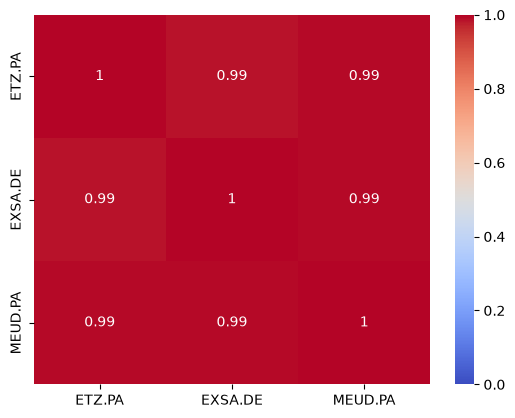

In [75]:
# Affichage de la matrice de corrélation en heatmap avec seaborn
import seaborn as sns
sns.heatmap(cor,annot=True, vmin=0, vmax=1, cmap="coolwarm")

| | ETZ.PA | EXSA.DE | MEUD.PA |
|---|---|---|---|
| ETZ.PA | 1,000 | 0,988 | 0,993 |
| EXSA.DE | 0,988 | 1,000 | 0,994 |
| MEUD.PA | 0,993 | 0,994 | 1,000 |

Les trois coefficients dépassent 0,98. Le résultat est attendu et confirme la cohérence
des données : trois fonds détenant les mêmes 600 actions ne peuvent pas réagir
différemment aux mêmes séances. L'écart résiduel, de l'ordre du centième, vient des
décalages de place de cotation et des différences de réplication observées au notebook 04.

La conséquence pour un portefeuille est directe : **détenir les trois ne diversifie rien.**
Trois lignes sur un relevé, un seul risque. Répartir 100 000 € entre MEUD.PA, ETZ.PA et
EXSA.DE expose exactement au même choc que de placer la totalité sur l'un des trois — le
creux d'avril 2025 les a fait reculer ensemble de 16 %.

La diversification suppose des actifs qui ne réagissent pas aux mêmes chocs, donc des
corrélations faibles. C'est l'objet de la suite : ajouter une classe obligataire et
mesurer sa corrélation avec les actions.

## 3. Ajouter une classe obligataire

IEGA.AS (iShares Core € Govt Bond) détient plusieurs centaines d'emprunts d'État de la
zone euro, toutes maturités confondues. La nature de l'actif diffère : une action est une
part de société dont la valeur dépend des bénéfices attendus, une obligation une créance
dont la valeur dépend des taux d'intérêt.

In [76]:
# Télécharger un historique de cours d'un ETF d'obligations d'Etat
import yfinance as yf
bond = yf.download("IEGA.AS", start=etf_eur.index[0])
bond

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,IEGA.AS,IEGA.AS,IEGA.AS,IEGA.AS,IEGA.AS
Date,,,,,
2024-02-19,103.298965,103.449867,103.242381,103.374416,1929
2024-02-20,103.591324,103.638482,103.336687,103.336687,5680
2024-02-21,102.987732,103.449862,102.987732,103.364978,1189
2024-02-22,103.232941,103.308391,102.714234,102.978304,7955
2024-02-23,103.770515,103.770515,102.968872,103.166925,1749
...,...,...,...,...,...
2026-10-12,104.540001,104.790001,104.540001,104.790001,880
2026-10-13,104.750000,104.879997,104.750000,104.870003,87


In [77]:
# Joindre la colonne Close de l'ETF dobligations à etf_eur
etf_bonds_eur = bond["Close"]
actions_obligations = etf_eur.join(etf_bonds_eur)
actions_obligations = actions_obligations.dropna()
actions_obligations

,ETZ.PA,EXSA.DE,MEUD.PA,IEGA.AS
Date,,,,
2024-02-19,15.112000,45.084953,223.820007,103.298965
2024-02-20,15.094000,45.010891,223.429993,103.591324
2024-02-21,15.066000,44.936844,223.139999,102.987732
2024-02-22,15.198000,45.353394,225.250000,103.232941
2024-02-23,15.258000,45.501503,226.190002,103.770515
...,...,...,...,...
2026-09-21,21.174999,63.509998,316.600006,105.489998
2026-09-22,21.190001,63.580002,316.950012,105.449997
2026-09-23,21.100000,63.360001,315.850006,104.769997


In [78]:
# La date manquante entre etf_eur et actions_obligations
etf_eur.index.difference(actions_obligations.index)

DatetimeIndex(['2026-03-06'], dtype='datetime64[us]', name='Date', freq=None)

In [79]:
# Sauvegarde des données actions_obligations
actions_obligations.to_csv("data/actions_obligations.csv")

In [80]:
# Rendements journaliers
actions_obligations_returns = actions_obligations.pct_change()
actions_obligations_returns = actions_obligations_returns.dropna()
actions_obligations_returns

,ETZ.PA,EXSA.DE,MEUD.PA,IEGA.AS
Date,,,,
2024-02-20,-0.001191,-0.001643,-0.001743,0.002830
2024-02-21,-0.001855,-0.001645,-0.001298,-0.005827
2024-02-22,0.008761,0.009270,0.009456,0.002381
2024-02-23,0.003948,0.003266,0.004173,0.005207
2024-02-26,-0.002884,-0.003662,-0.004156,-0.005362
...,...,...,...,...
2026-09-21,0.010740,0.010662,0.010211,0.004954
2026-09-22,0.000708,0.001102,0.001106,-0.000379
2026-09-23,-0.004247,-0.003460,-0.003471,-0.006449


In [81]:
# Rendement annualisé
performance = actions_obligations.iloc[-1]/actions_obligations.iloc[0]
n_years = (actions_obligations.index[-1] - actions_obligations.index[0]).days/365.25
taux_annualise_ao = performance**(1/n_years) - 1
taux_annualise_ao

ETZ.PA     0.136461
EXSA.DE    0.139031
MEUD.PA    0.140775
IEGA.AS    0.004311
dtype: float64

In [82]:
# Volatilité annualisée
volat_annualisee_ao = actions_obligations_returns.std()*252**0.5
volat_annualisee_ao

ETZ.PA     0.131507
EXSA.DE    0.131487
MEUD.PA    0.132819
IEGA.AS    0.045509
dtype: float64

In [83]:
# Max drawdown
actions_obligations_b100 = actions_obligations*100/actions_obligations.iloc[0]
max_glissant = actions_obligations_b100.cummax()
drawdown = (actions_obligations_b100 - max_glissant)/max_glissant
max_dd = drawdown.min()
max_dd

ETZ.PA    -0.162778
EXSA.DE   -0.163286
MEUD.PA   -0.161798
IEGA.AS   -0.051223
dtype: float64

In [84]:
# Ratio de Sharpe à 2%
sharpe_ao = (taux_annualise_ao-0.02)/volat_annualisee_ao
sharpe_ao

ETZ.PA     0.885585
EXSA.DE    0.905264
MEUD.PA    0.909322
IEGA.AS   -0.344747
dtype: float64

In [85]:
recap = pd.DataFrame({"Rendement annualisé":taux_annualise_ao, "Volatilité annualisée": volat_annualisee_ao,
                     "Drawdown max":max_dd, "Ratio de Sharpe 2%":sharpe_ao})
recap

,Rendement annualisé,Volatilité annualisée,Drawdown max,Ratio de Sharpe 2%
ETZ.PA,0.136461,0.131507,-0.162778,0.885585
EXSA.DE,0.139031,0.131487,-0.163286,0.905264
MEUD.PA,0.140775,0.132819,-0.161798,0.909322
IEGA.AS,0.004311,0.045509,-0.051223,-0.344747


In [86]:
# Calcul de la corrélation
cor_ao = actions_obligations_returns.corr()
cor_ao

,ETZ.PA,EXSA.DE,MEUD.PA,IEGA.AS
ETZ.PA,1.000000,0.988240,0.992554,0.285549
EXSA.DE,0.988240,1.000000,0.994470,0.287974
MEUD.PA,0.992554,0.994470,1.000000,0.285524
IEGA.AS,0.285549,0.287974,0.285524,1.000000


<Axes: >

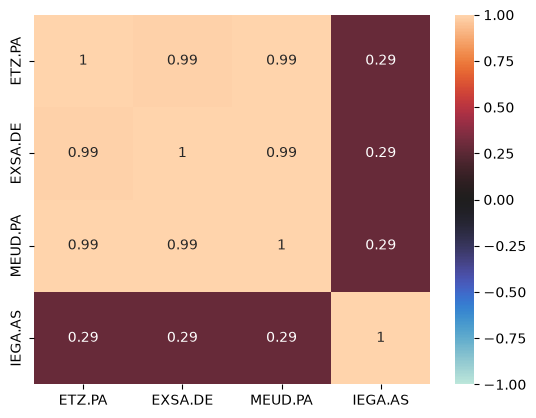

In [87]:
# Affichage de la matrice de corrélation en heatmap avec seaborn
sns.heatmap(cor_ao, annot=True, vmin=-1, vmax=1, center=0)

659 séances communes aux trois places de cotation sur les 660 retenues pour les actions.
La seule séance écartée, le 6 mars 2026, est une absence de cotation sur IEGA.AS.

| | Rendement annualisé | Volatilité annualisée | Max drawdown | Sharpe (2 %) |
|---|---|---|---|---|
| ETZ.PA | 13,65 % | 13,15 % | −16,28 % | 0,89 |
| EXSA.DE | 13,90 % | 13,15 % | −16,33 % | 0,91 |
| MEUD.PA | 14,08 % | 13,28 % | −16,18 % | 0,91 |
| IEGA.AS | 0,43 % | 4,55 % | −5,12 % | −0,34 |

**Le risque est trois fois plus faible.** 4,55 % de volatilité contre 13,2 %, et un
drawdown maximal de 5,12 % contre 16,3 %. Un État rembourse un montant connu à une
échéance connue : le prix d'une obligation ne peut pas varier comme le bénéfice d'une
entreprise.

**Le rendement l'est aussi, et plus que prévu.** 0,43 % par an sur la période, coupons
réinvestis. Un placement monétaire sans risque rapportait 2 à 3 % sur la même fenêtre,
d'où un ratio de Sharpe négatif : le fonds obligataire a moins rapporté que de laisser
l'argent sur un compte rémunéré, tout en exposant à un risque de 4,5 %. L'explication
tient au niveau des taux hérité de 2022 et au recul de valeur des titres longs déjà
émis, qui a absorbé la quasi-totalité des coupons encaissés.

**La corrélation avec les actions est de +0,29.** Positive, pas négative.

C'est le résultat qui mérite le plus d'attention. Le manuel classique présente les
obligations comme un amortisseur : quand les actions baissent, elles montent. Cette
relation a tenu sur les deux décennies précédant 2022. Elle ne tient plus de la même
façon : quand l'inflation fait monter les taux, actions et obligations reculent
ensemble, ce qui s'est produit en 2022 pour la première fois depuis des décennies. Les
+0,29 mesurés ici confirment que les deux classes bougent plutôt dans le même sens sur
2024-2026, même faiblement.

**Ce que cela change pour un portefeuille.** La diversification reste réelle, mais elle
ne vient pas de la corrélation : elle vient du niveau de risque. À +0,29, mélanger les
deux classes réduit la volatilité d'ensemble bien davantage que de détenir les trois ETF
actions entre eux, corrélés à 0,99. Reste la question du prix de cette réduction : sur
cette fenêtre, chaque point de volatilité évité a coûté du rendement.

C'est l'arbitrage que le portefeuille 60/40 quantifiera.

## Conclusion

Trois résultats ressortent de ce notebook, chacun remettant en cause une habitude de lecture.

**Un ratio de Sharpe ne se lit pas seul.** Celui de MEUD.PA vaut 1,06 ou 0,84 selon qu'on
retient 0 % ou 3 % de taux sans risque, soit 21 % d'écart pour un paramètre que les fiches
de fonds mentionnent rarement. Deux ratios ne se comparent qu'à hypothèse identique.

**Multiplier les lignes n'est pas diversifier.** Les trois ETF actions sont corrélés à plus
de 0,98 : ils détiennent les mêmes 600 actions et ont reculé ensemble de 16 % en avril 2025.
Trois lignes sur un relevé, un seul risque.

**La classe obligataire décorrèle, mais pas comme le dit le manuel.** À +0,29, la
corrélation avec les actions est faible mais positive, là où la théorie classique attend une
relation inverse. Cette relation a tenu jusqu'en 2022 ; depuis, une hausse des taux fait
reculer les deux classes ensemble. L'apport de IEGA.AS tient donc moins à sa décorrélation
qu'à son niveau de risque, trois fois inférieur à celui des actions.

Reste à chiffrer le coût de cette réduction de risque : sur la période, le fonds obligataire
rapporte 0,43 % par an, moins qu'un placement monétaire sans risque. Mélanger les deux
classes réduit la volatilité, mais au prix du rendement. C'est l'arbitrage que mesurera le
prochain notebook, consacré à un portefeuille 60/40 avec rééquilibrage trimestriel.